# Titanic Survival – Random Forest (v2)
v2 adds Title, age-by-title and HasCabin features and picks model settings by repeated cross-validation. It ends with a family-group model, which writes the final `submission.csv`. The Random Forest predictions are kept as `submission_random_forest.csv`. Run all cells, then submit `submission.csv` from the Output tab.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/gender_submission.csv
/kaggle/input/competitions/titanic/test.csv


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import pandas as pd
import numpy as np
import glob

# Find the Titanic files wherever Kaggle attached them
# (add the data first: right panel -> + Add Input -> "Titanic - Machine Learning from Disaster")
train_files = glob.glob('/kaggle/input/**/train.csv', recursive=True)
test_files = glob.glob('/kaggle/input/**/test.csv', recursive=True)
if not train_files or not test_files:
    raise FileNotFoundError("Titanic data not found. Click '+ Add Input' and add the Titanic competition data.")

train_data = pd.read_csv(train_files[0])
test_data = pd.read_csv(test_files[0])
print("Using:", train_files[0], "and", test_files[0])
print("Datasets successfully loaded!")

Using: /kaggle/input/competitions/titanic/train.csv and /kaggle/input/competitions/titanic/test.csv
Datasets successfully loaded!


In [3]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Check dataset information
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
train_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
missing_values = train_data.isnull().sum()

print(missing_values)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
missing_percentage = (train_data.isnull().sum() / len(train_data)) * 100

print(missing_percentage.round(2))

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


In [8]:
# Count passengers by survival status
train_data['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [9]:
# Calculate survival percentage
train_data['Survived'].value_counts(normalize=True) * 100

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

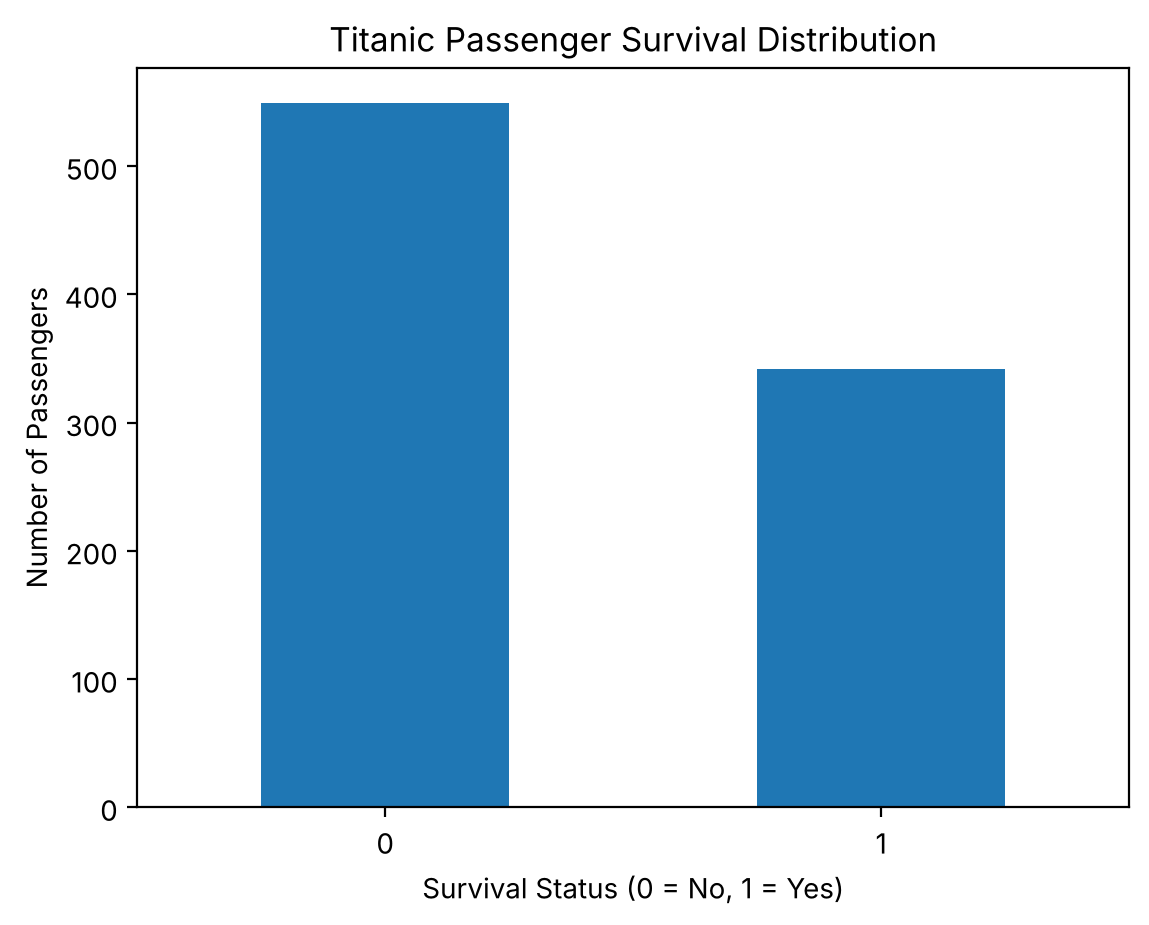

In [10]:
import matplotlib.pyplot as plt

train_data['Survived'].value_counts().plot(
    kind='bar',
    title='Titanic Passenger Survival Distribution'
)

plt.xlabel('Survival Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=0)
plt.show()

In [11]:
# Survival count by gender
train_data.groupby('Sex')['Survived'].value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64

In [12]:
# Survival rate by gender
survival_by_sex = train_data.groupby('Sex')['Survived'].mean() * 100

print(survival_by_sex)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


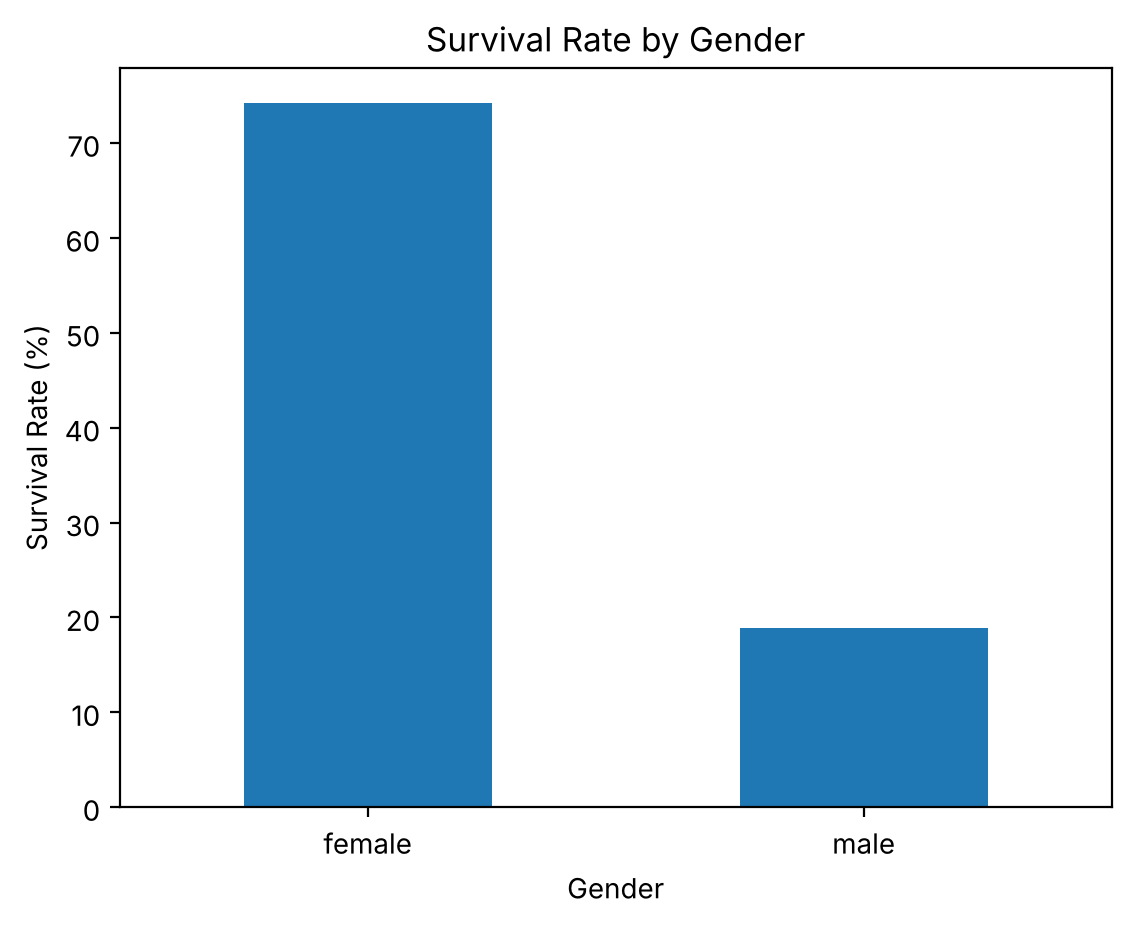

In [13]:
import matplotlib.pyplot as plt

survival_by_sex.plot(kind='bar', title='Survival Rate by Gender')

plt.xlabel('Gender')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [14]:
# Survival rate by passenger class
survival_by_class = train_data.groupby('Pclass')['Survived'].mean() * 100

print(survival_by_class)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


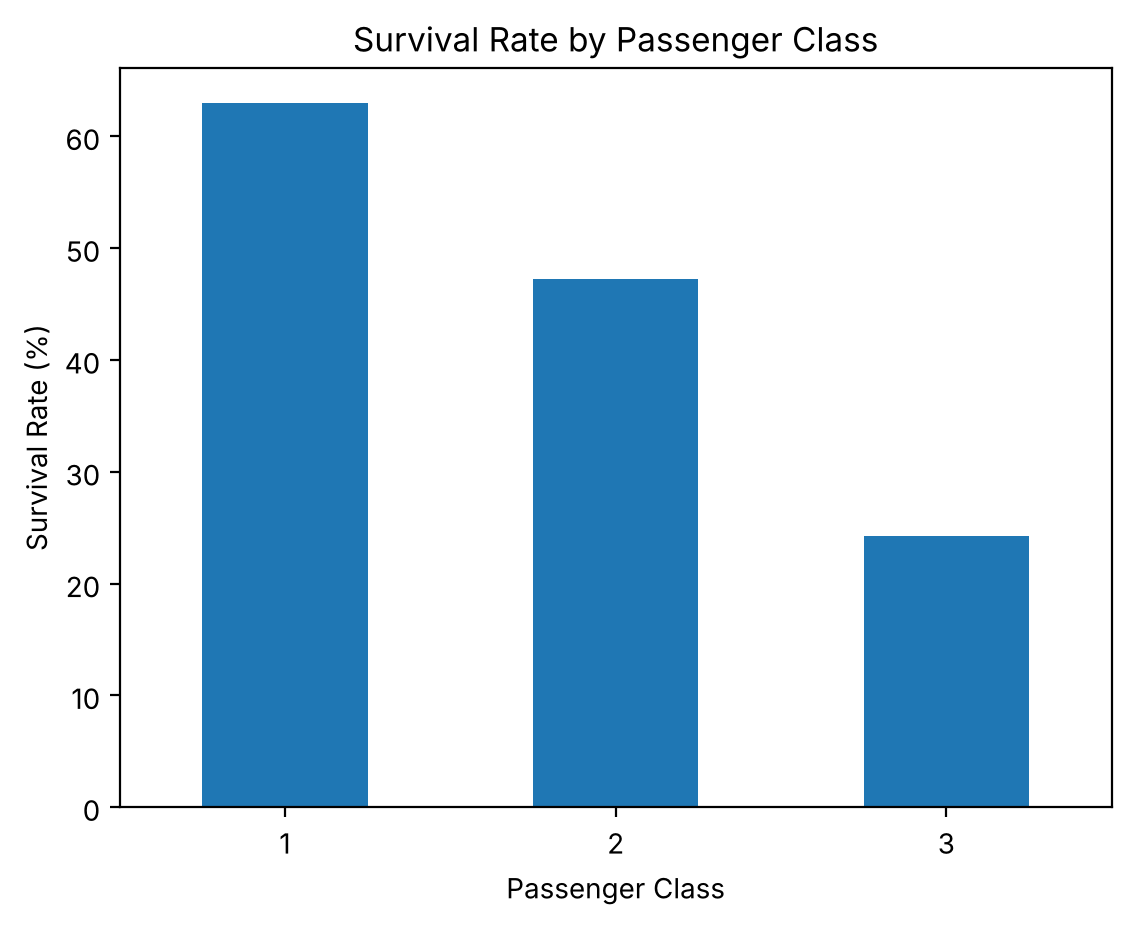

In [15]:
survival_by_class.plot(
    kind='bar',
    title='Survival Rate by Passenger Class'
)

plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [16]:
# Compare average age of survivors and non-survivors
survival_by_age = train_data.groupby('Survived')['Age'].mean()

print(survival_by_age)

Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64


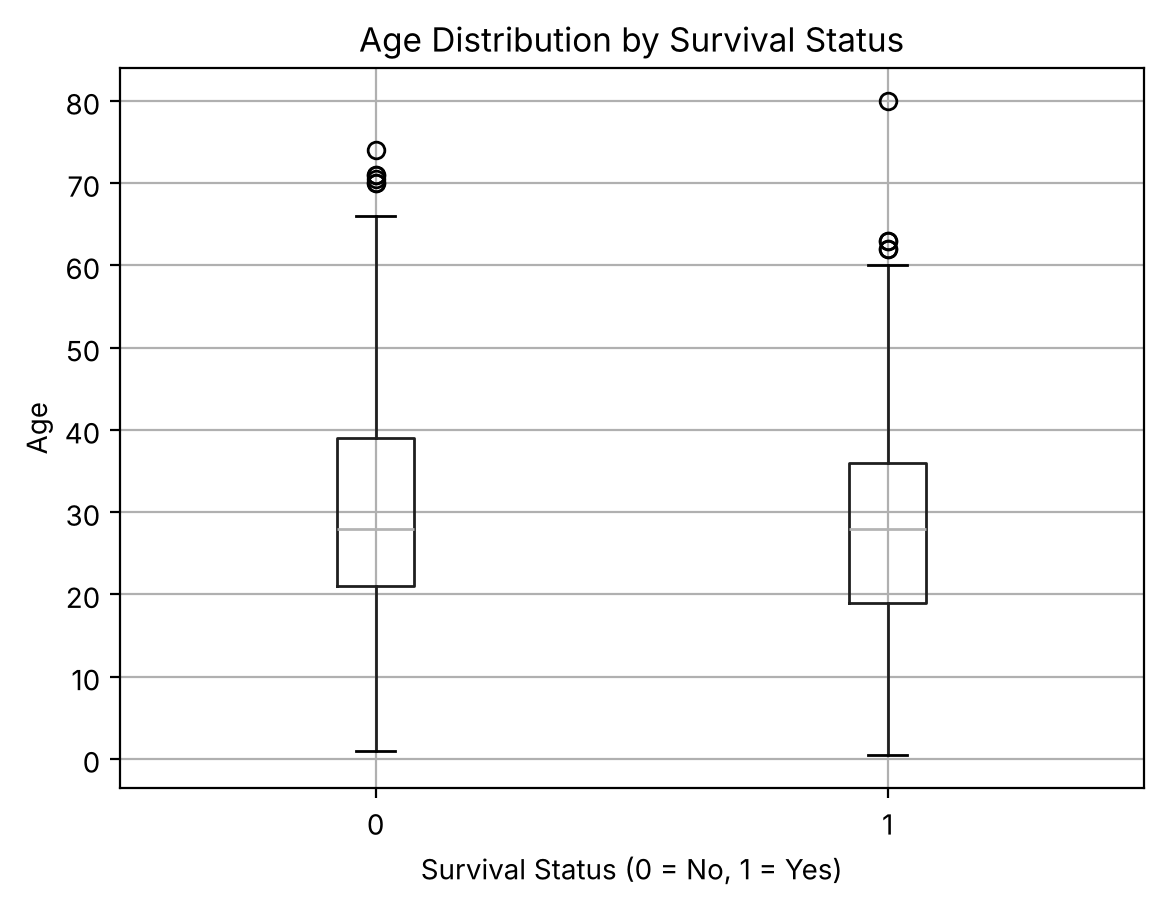

In [17]:
train_data.boxplot(column='Age', by='Survived')

plt.title('Age Distribution by Survival Status')
plt.suptitle('')
plt.xlabel('Survival Status (0 = No, 1 = Yes)')
plt.ylabel('Age')
plt.show()

In [18]:
# Calculate family size
train_data['FamilySize'] = train_data['SibSp'] + train_data['Parch'] + 1

# Display the first five records
train_data[['SibSp', 'Parch', 'FamilySize']].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [19]:
survival_by_family = train_data.groupby('FamilySize')['Survived'].mean() * 100

print(survival_by_family)

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64


In [20]:
def categorize_family(size):
    if size == 1:
        return 'Alone'
    elif size <= 4:
        return 'Small Family'
    else:
        return 'Large Family'

train_data['FamilyCategory'] = train_data['FamilySize'].apply(categorize_family)

print(train_data.groupby('FamilyCategory')['Survived'].mean() * 100)

FamilyCategory
Alone           30.353818
Large Family    16.129032
Small Family    57.876712
Name: Survived, dtype: float64


In [21]:
print(train_data['FamilyCategory'].value_counts())

FamilyCategory
Alone           537
Small Family    292
Large Family     62
Name: count, dtype: int64


In [22]:
# Calculate survival rates by family category
family_results = train_data.groupby('FamilyCategory')['Survived'].agg(
    ['count', 'sum', 'mean']
)

family_results.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

family_results['Survival Rate'] *= 100

print(family_results.round(2))

                Total Passengers  Survivors  Survival Rate
FamilyCategory                                            
Alone                        537        163          30.35
Large Family                  62         10          16.13
Small Family                 292        169          57.88


In [23]:
# Survival rate by embarkation port
survival_by_port = train_data.groupby('Embarked')['Survived'].agg(
    ['count', 'sum', 'mean']
)

survival_by_port.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

survival_by_port['Survival Rate'] *= 100

print(survival_by_port.round(2))

          Total Passengers  Survivors  Survival Rate
Embarked                                            
C                      168         93          55.36
Q                       77         30          38.96
S                      644        217          33.70


In [24]:
# Inspect categorical variables
print("Sex categories:")
print(train_data['Sex'].value_counts())

print("\nPassenger classes:")
print(train_data['Pclass'].value_counts())

print("\nEmbarkation ports:")
print(train_data['Embarked'].value_counts())

Sex categories:
Sex
male      577
female    314
Name: count, dtype: int64

Passenger classes:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Embarkation ports:
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


In [25]:
# Check missing values
missing_values = train_data.isnull().sum()

print(missing_values)

PassengerId         0
Survived            0
Pclass              0
Name                0
Sex                 0
Age               177
SibSp               0
Parch               0
Ticket              0
Fare                0
Cabin             687
Embarked            2
FamilySize          0
FamilyCategory      0
dtype: int64


In [26]:
# Calculate missing percentages
missing_percentage = (
    train_data.isnull().sum() / len(train_data)
) * 100

print(missing_percentage.round(2))

PassengerId        0.00
Survived           0.00
Pclass             0.00
Name               0.00
Sex                0.00
Age               19.87
SibSp              0.00
Parch              0.00
Ticket             0.00
Fare               0.00
Cabin             77.10
Embarked           0.22
FamilySize         0.00
FamilyCategory     0.00
dtype: float64


## Feature engineering (v2)
Three new features, applied to both train and test:
- **Title** from the passenger's name (Mr, Mrs, Miss, Master, Rare). It captures sex, age group and status together. "Master" marks young boys, who had much higher survival than adult men.
- **Age filled by title**: missing ages use the median age of passengers with the same title, instead of one overall median.
- **HasCabin**: whether a cabin number is recorded, a rough proxy for wealth and deck location.

In [27]:
# Title from name
for df in (train_data, test_data):
    df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.')[0]
    df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')
    df.loc[~df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Title'] = 'Rare'

# Fill missing ages with the median age for each title (medians from training data only)
age_by_title = train_data.groupby('Title')['Age'].median()
for df in (train_data, test_data):
    df['Age'] = df['Age'].fillna(df['Title'].map(age_by_title))

# Cabin recorded or not
for df in (train_data, test_data):
    df['HasCabin'] = df['Cabin'].notna().astype(int)

# Family size for both datasets
for df in (train_data, test_data):
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

print(age_by_title.round(1))
print(train_data.groupby('Title')['Survived'].agg(['count', 'mean']).round(2))

Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64
        count  mean
Title              
Master     40  0.57
Miss      185  0.70
Mr        517  0.16
Mrs       126  0.79
Rare       23  0.35


In [28]:
# Select features for the machine learning model
features = [
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked',
    'FamilySize',
    'Title',
    'HasCabin'
]

# Define predictors and target
X = train_data[features]
y = train_data['Survived']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (891, 10)
Target shape: (891,)


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Validation records:", X_valid.shape[0])

Training records: 712
Validation records: 179


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical features
numerical_features = [
    'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin'
]

categorical_features = [
    'Sex', 'Embarked', 'Title'
]

# Numerical preprocessing
numerical_transformer = SimpleImputer(strategy='median')

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [31]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [32]:
# Train the model
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [33]:
# Predict survival for validation data
y_pred = model.predict(X_valid)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[0 0 0 0 1 1 1 1 0 0]


In [34]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 81.56 %


In [35]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



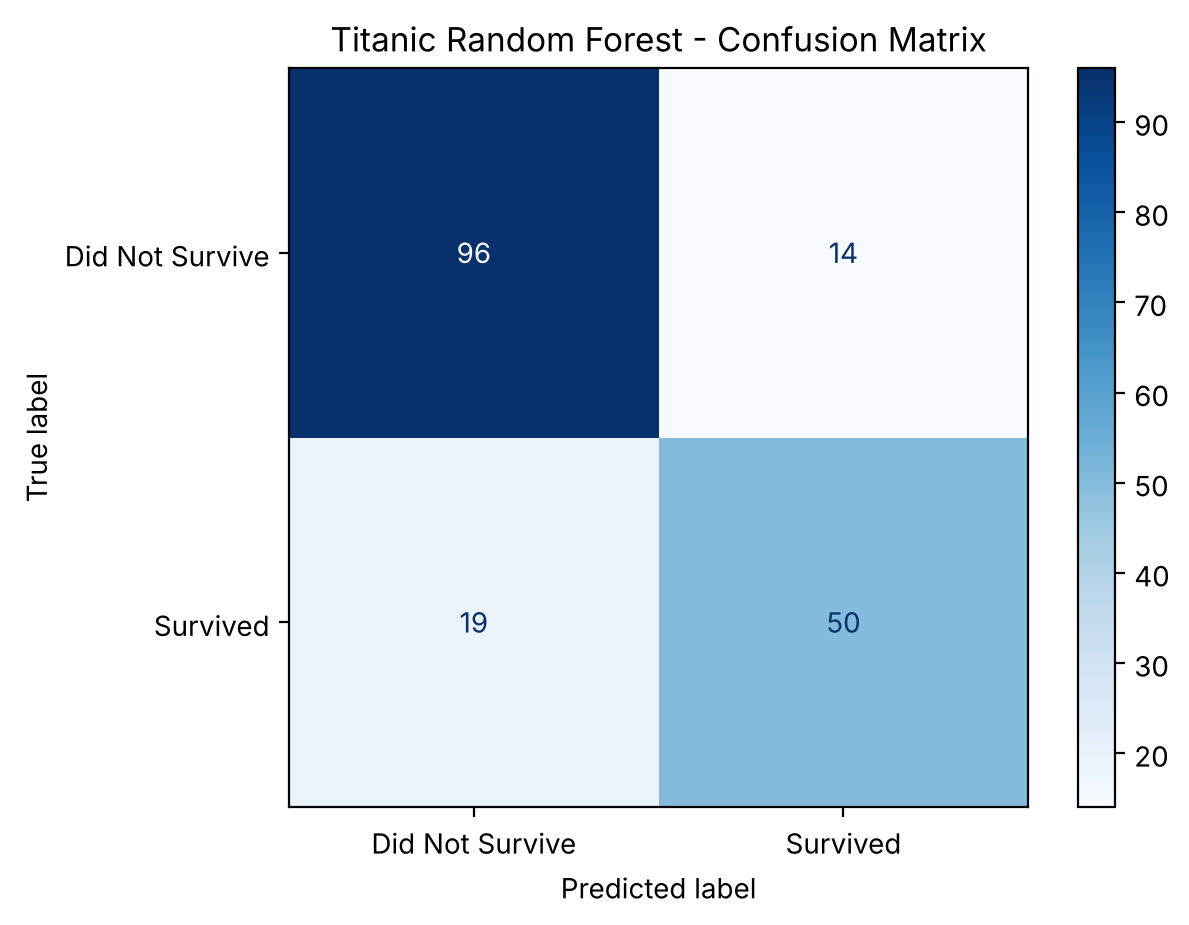

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_valid, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Did Not Survive', 'Survived']
)

display.plot(cmap='Blues')
plt.title('Titanic Random Forest - Confusion Matrix')
plt.show()

In [37]:
# Get the names of the processed features
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# Get the importance scores from Random Forest
importances = model.named_steps['classifier'].feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort from highest to lowest importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display the results
print(importance_df)

              Feature  Importance
8       cat__Sex_male    0.171093
14      cat__Title_Mr    0.169170
7     cat__Sex_female    0.126107
4           num__Fare    0.090213
0         num__Pclass    0.082941
1            num__Age    0.075592
6       num__HasCabin    0.060665
5     num__FamilySize    0.056893
15     cat__Title_Mrs    0.044667
13    cat__Title_Miss    0.044195
2          num__SibSp    0.024370
3          num__Parch    0.016013
12  cat__Title_Master    0.009774
11    cat__Embarked_S    0.008952
9     cat__Embarked_C    0.008260
16    cat__Title_Rare    0.006265
10    cat__Embarked_Q    0.004829


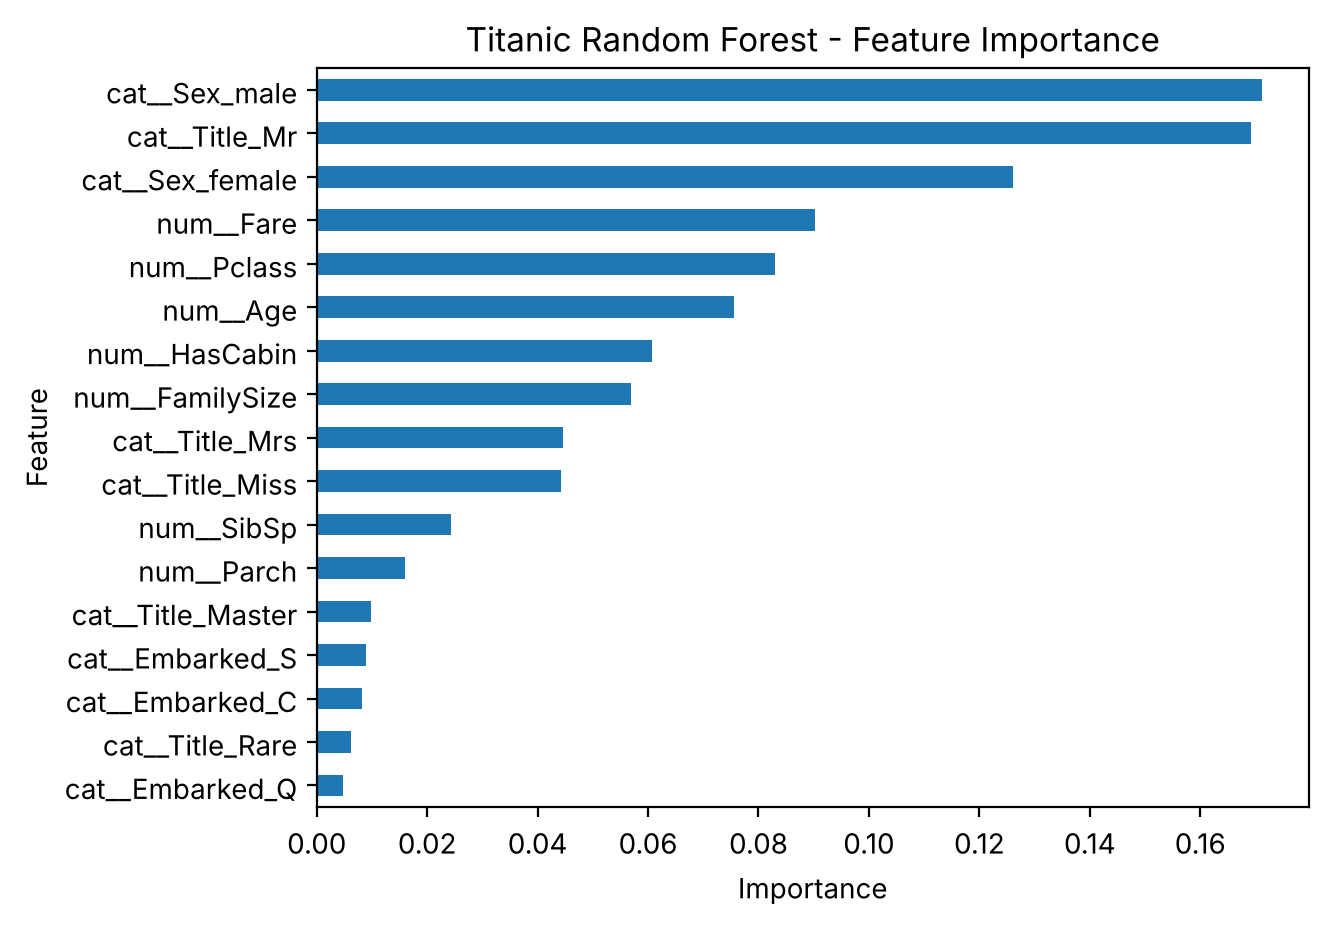

In [38]:
importance_df.sort_values('Importance').plot(
    x='Feature',
    y='Importance',
    kind='barh',
    legend=False,
    title='Titanic Random Forest - Feature Importance'
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [39]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Set up 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the Random Forest model
cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

# Display results
print("Cross-validation scores:", cv_scores)
print("Mean accuracy:", round(cv_scores.mean() * 100, 2), "%")
print("Standard deviation:", round(cv_scores.std() * 100, 2), "%")

Cross-validation scores: [0.83240223 0.82022472 0.83146067 0.83146067 0.83707865]
Mean accuracy: 83.05 %
Standard deviation: 0.56 %


In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# Define three models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    )
}

# Evaluate each model
for name, classifier in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', classifier)
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring='accuracy'
    )

    print(name)
    print("Mean Accuracy:", round(scores.mean() * 100, 2), "%")
    print("Standard Deviation:", round(scores.std() * 100, 2), "%")
    print("-----------------------------")

Logistic Regression
Mean Accuracy: 82.6 %
Standard Deviation: 1.3 %
-----------------------------
Decision Tree
Mean Accuracy: 81.7 %
Standard Deviation: 1.37 %
-----------------------------


Random Forest
Mean Accuracy: 83.05 %
Standard Deviation: 0.56 %
-----------------------------


In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Create the pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Define parameters to test
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5, 7, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Run grid search
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, y)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross-Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

Fitting 5 folds for each of 108 candidates, totalling 540 fits


Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Best Cross-Validation Accuracy:
84.4 %


In [42]:
# Retrieve the best tuned model
best_model = grid_search.best_estimator_

# Predict validation outcomes
y_pred_tuned = best_model.predict(X_valid)

# Calculate accuracy
from sklearn.metrics import accuracy_score

tuned_accuracy = accuracy_score(y_valid, y_pred_tuned)

print("Tuned Model Validation Accuracy:",
      round(tuned_accuracy * 100, 2), "%")

Tuned Model Validation Accuracy: 91.06 %


In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_valid, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.90      0.96      0.93       110
           1       0.93      0.83      0.88        69

    accuracy                           0.91       179
   macro avg       0.92      0.89      0.90       179
weighted avg       0.91      0.91      0.91       179



In [44]:
grid_search.fit(X, y)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [3, 5, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], 'classifier__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring``

In [45]:
print("grid_search_clean:", 'grid_search_clean' in globals())
print("grid_search:", 'grid_search' in globals())
print("best_model_clean:", 'best_model_clean' in globals())
print("clean_accuracy:", 'clean_accuracy' in globals())

grid_search_clean: False
grid_search: True
best_model_clean: False
clean_accuracy: False


In [46]:
print("Original Best Parameters:")
print(grid_search.best_params_)

print("\nOriginal Cross-Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

Original Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}

Original Cross-Validation Accuracy:
84.4 %


In [47]:
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (712, 10)
X_valid: (179, 10)
y_train: (712,)
y_valid: (179,)


In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the tuned Random Forest pipeline
best_model_clean = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=7,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    ))
])

# Train using only the 712 training records
best_model_clean.fit(X_train, y_train)

print("Tuned model training completed!")

Tuned model training completed!


In [49]:
from sklearn.metrics import accuracy_score, classification_report

# Generate predictions
y_pred_clean = best_model_clean.predict(X_valid)

# Calculate validation accuracy
clean_accuracy = accuracy_score(y_valid, y_pred_clean)

print("Independent Validation Accuracy:",
      round(clean_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_valid, y_pred_clean))

Independent Validation Accuracy: 80.45 %

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.87      0.85       110
           1       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [50]:
# Create a balanced Random Forest
balanced_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=7,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
balanced_model.fit(X_train, y_train)

# Predict validation outcomes
y_pred_balanced = balanced_model.predict(X_valid)

# Evaluate
print(classification_report(y_valid, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83       110
           1       0.71      0.80      0.75        69

    accuracy                           0.80       179
   macro avg       0.79      0.80      0.79       179
weighted avg       0.81      0.80      0.80       179



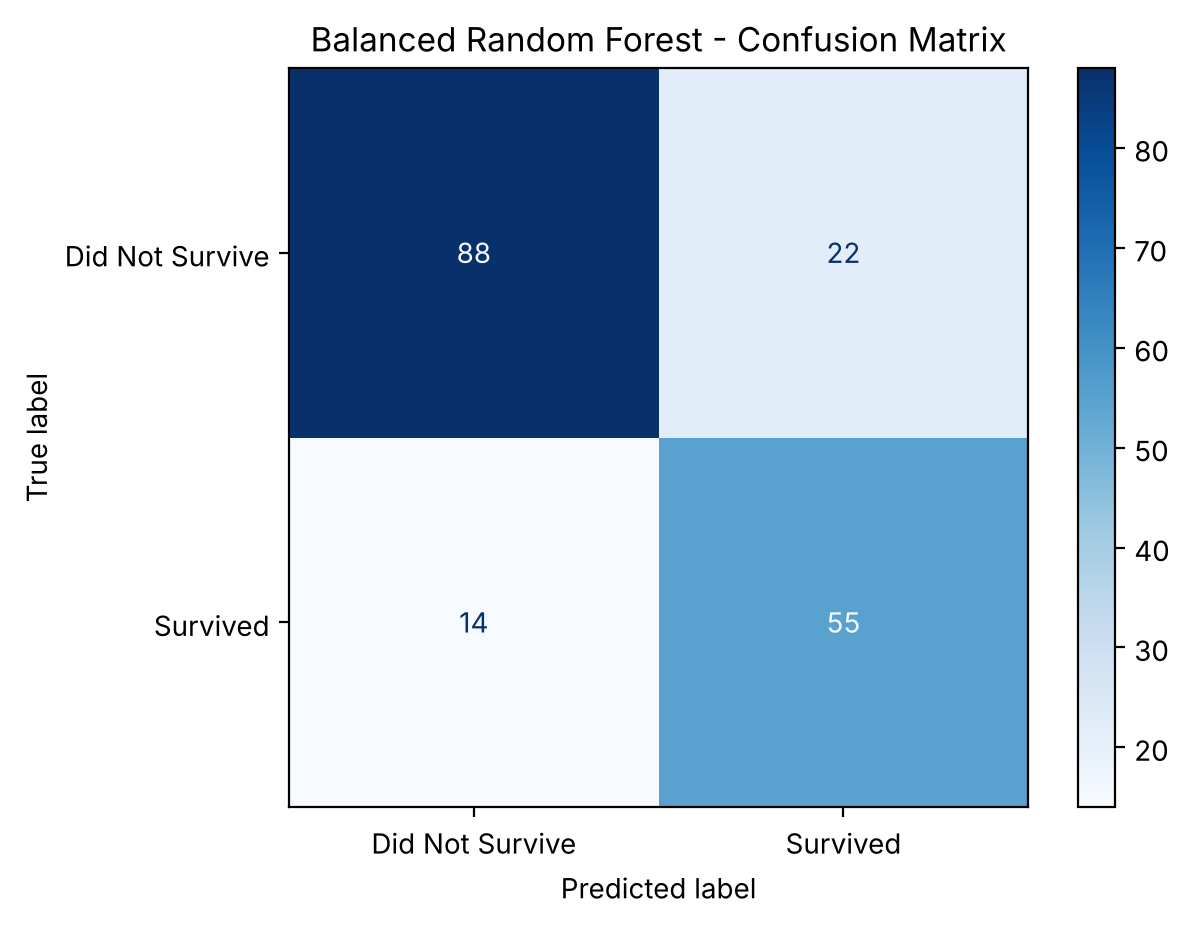

[[88 22]
 [14 55]]


In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_valid, y_pred_balanced)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Did Not Survive', 'Survived']
)

display.plot(cmap='Blues')
plt.title('Balanced Random Forest - Confusion Matrix')
plt.show()

print(cm)

## Final model choice (v2)
Settings were chosen by **repeated cross-validation** (5 folds × 5 repeats) on all 891 training passengers, not by the single 179-row validation split, which is too small to tune on reliably.

| Version | CV accuracy |
|---|---|
| v1: original features, depth 7, balanced weights | 81.7% |
| Original features, depth 5 | 82.2% |
| **v2: + Title, age by title, HasCabin, depth 5** | **83.0%** |

A shallower forest (depth 5) generalised better than depth 7, and balanced class weights did not help. The grid search above can pick a different "best" setting, but its top candidates are within a fraction of a percent of each other on a single 5-fold split; the repeated CV is the more reliable guide.

Note: the earlier 89.94% "tuned" validation score was inflated, because the grid search had already seen the validation rows. Retraining on the training split only gave an honest 80.45%.

In [52]:
# Train the final model using all training records
final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=2,
        random_state=42
    ))
])

final_model.fit(X, y)

print("Final model trained successfully!")

Final model trained successfully!


In [53]:
# Create FamilySize in the test dataset
test_data['FamilySize'] = (
    test_data['SibSp'] + test_data['Parch'] + 1
)

# Select the same features used during training
X_test = test_data[features]

print("Test dataset prepared!")
print("Test records:", X_test.shape[0])
print("Features:", X_test.shape[1])

Test dataset prepared!
Test records: 418
Features: 10


In [54]:
# Predict survival for the 418 passengers
test_predictions = final_model.predict(X_test)

print("Predictions generated successfully!")
print("Total predictions:", len(test_predictions))

print("First 10 predictions:")
print(test_predictions[:10])

Predictions generated successfully!
Total predictions: 418
First 10 predictions:
[0 1 0 0 1 0 1 0 1 0]


In [55]:
# Create the submission DataFrame
submission = pd.DataFrame({
    'PassengerId': test_data['PassengerId'],
    'Survived': test_predictions
})

# Save the CSV file
submission.to_csv('submission_random_forest.csv', index=False)

print("Random Forest submission saved as submission_random_forest.csv")
print(submission.head())

Random Forest submission saved as submission_random_forest.csv
   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1


In [56]:
print("Submission shape:", submission.shape)

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPrediction distribution:")
print(submission['Survived'].value_counts())

print("\nColumn names:")
print(submission.columns.tolist())

Submission shape: (418, 2)

Missing values:
PassengerId    0
Survived       0
dtype: int64

Prediction distribution:
Survived
0    254
1    164
Name: count, dtype: int64

Column names:
['PassengerId', 'Survived']


In [57]:
import os

print(os.path.exists('/kaggle/working/submission_random_forest.csv'))
print(os.path.getsize('/kaggle/working/submission_random_forest.csv'), "bytes")

True
2839 bytes


## Family-group model (woman-child-group)
Families on the Titanic tended to live or die together. This rule-based model, popularised on Kaggle by Chris Deotte, starts from the gender rule and adjusts it using each family's outcome in the training data:

1. **Base rule:** women survive, men do not.
2. **Families** are passengers sharing surname, class, ticket (without its last digit), port and fare. Passengers not matched by surname are linked by ticket.
3. Using only **women and boys** ("Master") in the training data:
   - if all of a family's women and boys **died**, predict that family's women in the test set **die**;
   - if all of a family's women and boys **survived**, predict that family's boys **survive**.

In [58]:
def add_group_features(df):
    df = df.copy()
    df['TitleRaw'] = df['Name'].str.extract(r',\s*([^\.]+)\.')[0]
    df['Surname'] = df['Name'].str.split(',').str[0]
    df['IsBoy'] = df['TitleRaw'] == 'Master'
    df['IsWoman'] = df['Sex'] == 'female'
    df['WomanOrChild'] = df['IsBoy'] | df['IsWoman']
    df['Group'] = (df['Surname'] + '-' + df['Pclass'].astype(str) + '-' + df['Ticket'].str[:-1] + '-'
                   + df['Embarked'].fillna('S') + '-' + df['Fare'].round(2).astype(str))
    return df

def family_group_predict(train, test):
    """Gender rule adjusted by how each family's women and boys fared in `train`."""
    preds = test['IsWoman'].astype(int).values.copy()
    by_group = train[train['WomanOrChild']].groupby('Group')['Survived'].mean()
    by_ticket = train[train['WomanOrChild']].groupby('Ticket')['Survived'].mean()
    for i, (_, row) in enumerate(test.iterrows()):
        if row['Group'] in by_group.index:
            rate = by_group[row['Group']]
        elif row['Ticket'] in by_ticket.index:
            rate = by_ticket[row['Ticket']]
        else:
            continue
        if row['IsWoman'] and rate == 0:
            preds[i] = 0
        if row['IsBoy'] and rate == 1:
            preds[i] = 1
    return preds

all_passengers = add_group_features(pd.concat([train_data, test_data], ignore_index=True))
train_g = all_passengers.iloc[:len(train_data)].copy()
test_g = all_passengers.iloc[len(train_data):].copy()
train_g['Survived'] = train_data['Survived'].values
print("Families with a woman or boy in training:", train_g.loc[train_g['WomanOrChild'], 'Group'].nunique())

Families with a woman or boy in training: 276


### Cross-validation
The family rules are rebuilt from the training folds only, so the score is not inflated.

In [59]:
from sklearn.model_selection import RepeatedStratifiedKFold

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
gender_scores, family_scores = [], []
for train_idx, valid_idx in cv_rep.split(train_g, train_g['Survived']):
    A, B = train_g.iloc[train_idx], train_g.iloc[valid_idx]
    gender_scores.append((B['IsWoman'].astype(int).values == B['Survived'].values).mean())
    family_scores.append((family_group_predict(A, B) == B['Survived'].values).mean())

print("Gender rule only:     ", round(np.mean(gender_scores) * 100, 2), "% ±", round(np.std(gender_scores) * 100, 2))
print("Gender + family rule: ", round(np.mean(family_scores) * 100, 2), "% ±", round(np.std(family_scores) * 100, 2))

Gender rule only:      78.68 % ± 2.57
Gender + family rule:  84.13 % ± 2.55


### Final submission

In [60]:
family_preds = family_group_predict(train_g, test_g)

changed = test_g[family_preds != test_g['IsWoman'].astype(int).values]
print("Passengers changed from the gender rule:", len(changed))
print(changed[['PassengerId', 'Name', 'Sex', 'Pclass']].to_string(index=False))

submission = pd.DataFrame({'PassengerId': test_data['PassengerId'], 'Survived': family_preds})
submission.to_csv('submission.csv', index=False)
print("\nsubmission.csv saved:", submission.shape, "| predicted survivors:", submission['Survived'].sum())

Passengers changed from the gender rule: 17
 PassengerId                                              Name    Sex  Pclass
         910                      Ilmakangas, Miss. Ida Livija female       3
         925 Johnston, Mrs. Andrew G (Elizabeth Lily" Watson)" female       3
         929                                Cacic, Miss. Manda female       3
         956                       Ryerson, Master. John Borie   male       1
         981                       Wells, Master. Ralph Lester   male       2
        1024                     Lefebre, Mrs. Frank (Frances) female       3
        1032                       Goodwin, Miss. Jessie Allis female       3
        1053                    Touma, Master. Georges Youssef   male       3
        1080                                   Sage, Miss. Ada female       3
        1086                     Drew, Master. Marshall Brines   male       2
        1088                   Spedden, Master. Robert Douglas   male       1
        1176        

## Results summary

| Model | CV accuracy | Public score |
|---|---|---|
| v1 Random Forest (depth 7, balanced) | 81.7% | 0.77511 |
| v2 Random Forest (+ Title, HasCabin, depth 5) | 83.0% | 0.77272 |
| **Family-group rule** | **84.1%** | **0.80143** |

The v2 Random Forest improved cross-validation but scored one passenger fewer on the leaderboard (0.7751 → 0.7727), a reminder that small CV gains do not always carry over to a 418-passenger test set. The family-group rule changed 17 predictions from the gender rule (0.76555) and lifted the score to 0.80143, 335 of 418 passengers correct.

**Citation:** Will Cukierski. *Titanic - Machine Learning from Disaster.* Kaggle, 2012. https://www.kaggle.com/competitions/titanic. Family-group idea: Chris Deotte's Titanic notebooks on Kaggle.